# Performance benchmark: FBP3D ToMoBAR on I13 dataset 2

Measure ten warm FBP3D reconstructions of I13 dataset 2. Synchronise each
measurement, exclude preprocessing and report timings with a reconstruction
preview. Timings describe this machine and run; no universal speed threshold applies.

## Data and execution

Use the named dataset archives from [Zenodo record 17252190](https://zenodo.org/records/17252190).
The repository downloader verifies the archive checksums.
Run from the repository root:

```bash
python .scripts/download_zenodo.py Zenodo
python -m pip install -e '.[validation]'
python -m pytest --nbmake --nbmake-timeout=1800 --overwrite docs/source/benchmarks/fbp3d_i13_dataset2.ipynb
```

Use an NVIDIA GPU with compatible CuPy and ToMoBAR installed, plus ASTRA for
ASTRA-based reconstruction. Run notebooks serially. Set `HTTOMOLIBGPU_DATA_DIR`
to use an archive stored elsewhere.

Documentation builds render saved outputs without running GPU computations.
Execute with `--overwrite` before building documentation to update the results.


In [1]:
import gc
import hashlib
import json
import os
import platform
from importlib.metadata import version
from pathlib import Path
from math import isclose

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np
import pytest
from numpy.testing import assert_allclose

from httomolibgpu.prep.normalize import dark_flat_field_correction, minus_log

repo_root = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "pyproject.toml").is_file() and (p / "httomolibgpu").is_dir()
    ),
    None,
)
configured_dir = os.environ.get("HTTOMOLIBGPU_DATA_DIR")
if configured_dir:
    data_dir = Path(configured_dir).expanduser()
elif repo_root is not None:
    data_dir = repo_root / "Zenodo"
else:
    raise FileNotFoundError("Set HTTOMOLIBGPU_DATA_DIR to the Zenodo archive directory")
props = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)
print(
    json.dumps(
        {
            "python": platform.python_version(),
            "packages": {
                name: version(name)
                for name in (
                    "httomolibgpu",
                    "tomobar",
                    "astra-toolbox",
                    "numpy",
                    "matplotlib",
                )
            },
            "cupy": cp.__version__,
            "cuda_runtime": cp.cuda.runtime.runtimeGetVersion(),
            "cuda_driver": cp.cuda.runtime.driverGetVersion(),
            "gpu": (
                props["name"].decode()
                if isinstance(props["name"], bytes)
                else props["name"]
            ),
        },
        indent=2,
    )
)
results = []


def force_clean_gpu_memory():
    gc.collect()
    cp.get_default_memory_pool().free_all_blocks()
    cp.get_default_pinned_memory_pool().free_all_blocks()


def load_dataset(name):
    path = data_dir / (name + ".npz")
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {path}; run .scripts/download_zenodo.py first"
        )
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    print(
        json.dumps(
            {
                "dataset": path.name,
                "zenodo_record": "17252190",
                "sha256": digest.hexdigest(),
            },
            indent=2,
        )
    )
    with np.load(path) as archive:
        if name == "i12_dataset3":
            return tuple(
                cp.asarray(archive[key]) for key in ("proj1", "proj2", "flats", "darks")
            )
        return (
            cp.asarray(archive["projdata"]),
            archive["angles"].copy(),
            cp.asarray(archive["flats"]),
            cp.asarray(archive["darks"]),
        )


def plot_comparison(before, after, title, label="Negative log transmission"):
    before, after = cp.asnumpy(before), cp.asnumpy(after)
    residual = before - after
    lo, hi = np.percentile(before[np.isfinite(before)], [1, 99])
    limit = float(np.percentile(np.abs(residual[np.isfinite(residual)]), 99)) or 1
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
    for ax, image, name, cmap, vmin, vmax in (
        (axes[0], before, "Before", "gray", lo, hi),
        (axes[1], after, "After", "gray", lo, hi),
        (axes[2], residual, "Removed component", "coolwarm", -limit, limit),
    ):
        im = ax.imshow(image, cmap=cmap, aspect="auto", vmin=vmin, vmax=vmax)
        ax.set(title=name, xlabel="Detector column", ylabel="Projection index")
        fig.colorbar(im, ax=ax, label=label)
    fig.suptitle(title)
    plt.show()
    plt.close(fig)


def check_results():
    print(json.dumps(results, indent=2))
    failed = [row for row in results if not row["passed"]]
    assert not failed, "Validation checks failed: " + json.dumps(failed, indent=2)
    print(f"All {len(results)} validation cases passed.")

{
  "python": "3.14.7",
  "packages": {
    "httomolibgpu": "6.0.1.post16+git.bbaa03d2.dirty",
    "tomobar": "2026.3.1.0",
    "astra-toolbox": "2.5.0",
    "numpy": "2.4.6",
    "matplotlib": "3.11.1"
  },
  "cupy": "14.2.0",
  "cuda_runtime": 13020,
  "cuda_driver": 13020,
  "gpu": "NVIDIA GeForce RTX 4060"
}


{
  "dataset": "i13_dataset2.npz",
  "zenodo_record": "17252190",
  "sha256": "11281ab163dd105ae5e550a411a5310d4156852a377eb058e66a765c68748461"
}


Input: (2501, 10, 2560) Parameters: {'center': 1286.25, 'detector_pad': 0, 'filter_freq_cutoff': 0.35}


{
  "samples_ms": [
    1649.7433999999998,
    1701.215857,
    1669.1100569999999,
    1700.2529749999999,
    1668.436909,
    1681.389694,
    1691.099548,
    1665.590129,
    1706.108013,
    1665.339806
  ],
  "mean_ms": 1679.8286388000001,
  "median_ms": 1675.2498755,
  "min_ms": 1649.7433999999998,
  "max_ms": 1706.108013
}


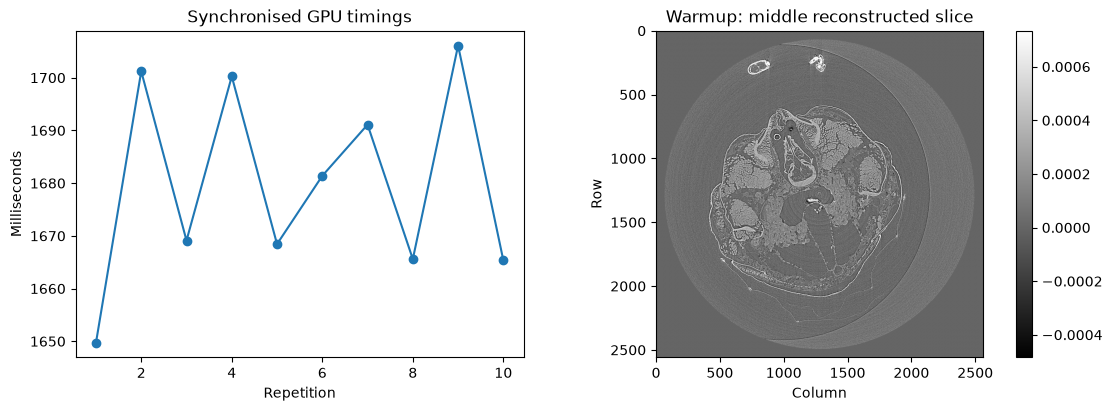

In [2]:
import time
from cupy.cuda import nvtx
from httomolibgpu.recon.algorithm import FBP3d_tomobar

dataset = load_dataset("i13_dataset2")
data_normalised = minus_log(
    dark_flat_field_correction(dataset[0], dataset[2], dataset[3])
)
angles = np.deg2rad(dataset[1])
del dataset
force_clean_gpu_memory()
parameters = {"center": 1286.25, "detector_pad": 0, "filter_freq_cutoff": 0.35}
print("Input:", data_normalised.shape, "Parameters:", parameters)
warmup = FBP3d_tomobar(data_normalised, angles, **parameters)
cp.cuda.Device().synchronize()
image = warmup[:, warmup.shape[1] // 2, :].get()
del warmup
force_clean_gpu_memory()
samples_ms = []
for repeat in range(10):
    cp.cuda.Device().synchronize()
    nvtx.RangePush("FBP3D measured reconstruction")
    start = time.perf_counter_ns()
    reconstruction = FBP3d_tomobar(data_normalised, angles, **parameters)
    cp.cuda.Device().synchronize()
    samples_ms.append((time.perf_counter_ns() - start) * 1e-6)
    nvtx.RangePop()
    del reconstruction
print(
    json.dumps(
        {
            "samples_ms": samples_ms,
            "mean_ms": float(np.mean(samples_ms)),
            "median_ms": float(np.median(samples_ms)),
            "min_ms": min(samples_ms),
            "max_ms": max(samples_ms),
        },
        indent=2,
    )
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(range(1, 11), samples_ms, "o-")
axes[0].set(
    xlabel="Repetition", ylabel="Milliseconds", title="Synchronised GPU timings"
)
lo, hi = np.percentile(image, [1, 99])
im = axes[1].imshow(image, cmap="gray", vmin=lo, vmax=hi)
axes[1].set(title="Warmup: middle reconstructed slice", xlabel="Column", ylabel="Row")
fig.colorbar(im, ax=axes[1])
plt.show()
plt.close(fig)
assert len(samples_ms) == 10
assert np.isfinite(samples_ms).all() and (np.asarray(samples_ms) > 0).all()
del image, data_normalised
force_clean_gpu_memory()